Este projeto tem como objetivo analisar os indicadores de felicidade mundial referentes ao ano de 2019

In [2]:
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
from google.colab import files

uploaded = files.upload()

Saving 2019.csv to 2019.csv


In [4]:
df = pd.read_csv("2019.csv")

In [25]:
df.head()

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


In [6]:
print("quantidade de linhas: ", df.shape[0])
print("quantidade de colunas: ", df.shape[1])

quantidade de linhas:  156
quantidade de colunas:  9


In [7]:
print(df.columns)

Index(['Overall rank', 'Country or region', 'Score', 'GDP per capita',
       'Social support', 'Healthy life expectancy',
       'Freedom to make life choices', 'Generosity',
       'Perceptions of corruption'],
      dtype='object')


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


In [9]:
df.isnull().sum()

,0
Overall rank,0
Country or region,0
Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
print("Paises diferentes: ", df["Country or region"].nunique())
print("Paises repetidos: ", df["Country or region"].duplicated().sum())

Paises diferentes:  156
Paises repetidos:  0


In [12]:
df.describe()

,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000
mean,78.500000,5.407096,0.905147,1.208814,0.725244,0.392571,0.184846,0.110603
std,45.177428,1.113120,0.398389,0.299191,0.242124,0.143289,0.095254,0.094538
min,1.000000,2.853000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,39.750000,4.544500,0.602750,1.055750,0.547750,0.308000,0.108750,0.047000
50%,78.500000,5.379500,0.960000,1.271500,0.789000,0.417000,0.177500,0.085500
75%,117.250000,6.184500,1.232500,1.452500,0.881750,0.507250,0.248250,0.141250
max,156.000000,7.769000,1.684000,1.624000,1.141000,0.631000,0.566000,0.453000


In [13]:
df.select_dtypes(include="number").lt(0).sum()

,0
Overall rank,0
Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,0


In [14]:
colunas_numericas = df.select_dtypes(include='number').columns


zeros_por_coluna = (df[colunas_numericas] == 0).sum()


print("Quantidade de valores zerados por coluna:")
print(zeros_por_coluna)

Quantidade de valores zerados por coluna:
Overall rank                    0
Score                           0
GDP per capita                  1
Social support                  1
Healthy life expectancy         1
Freedom to make life choices    1
Generosity                      1
Perceptions of corruption       1
dtype: int64


In [15]:
# Identificando países com valores zerados

for coluna in colunas_numericas:
    paises_zero = df.loc[df[coluna] == 0, "Country or region"]

    if len(paises_zero) > 0:
        print(f"\nColuna: {coluna}")
        print(paises_zero.to_list())


Coluna: GDP per capita
['Somalia']

Coluna: Social support
['Central African Republic']

Coluna: Healthy life expectancy
['Swaziland']

Coluna: Freedom to make life choices
['Afghanistan']

Coluna: Generosity
['Greece']

Coluna: Perceptions of corruption
['Moldova']


In [16]:
# Verificando valores negativos

valores_negativos = (df[colunas_numericas] < 0).sum()

print("Valores negativos por coluna:")
print(valores_negativos)

Valores negativos por coluna:
Overall rank                    0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
dtype: int64


In [17]:
# Indicadores que estamos investigando

indicadores = [
    'GDP per capita',
    'Social support',
    'Healthy life expectancy',
    'Freedom to make life choices',
    'Generosity',
    'Perceptions of corruption'
]

# Identificando países com pelo menos um valor zero

linhas_com_zero = df.loc[
    (df[indicadores] == 0).any(axis=1),
    ['Country or region'] + indicadores
]

# Exibindo os registros completos

display(linhas_com_zero)

,Country or region,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
70,Moldova,0.685,1.328,0.739,0.245,0.181,0.000
81,Greece,1.181,1.156,0.999,0.067,0.000,0.034
111,Somalia,0.000,0.698,0.268,0.559,0.243,0.270
134,Swaziland,0.811,1.149,0.000,0.313,0.074,0.135
153,Afghanistan,0.350,0.517,0.361,0.000,0.158,0.025
154,Central African Republic,0.026,0.000,0.105,0.225,0.235,0.035


### Diagnóstico de valores inconsistentes

Durante a etapa de validação dos dados, foram identificadas seis ocorrências de valores iguais a zero, distribuídas entre seis indicadores socioeconômicos diferentes.

Os registros identificados correspondem à Somália, República Centro-Africana, Essuatíni (Swaziland), Afeganistão, Grécia e Moldávia.

Também foi realizada uma verificação de valores negativos, não sendo identificada nenhuma ocorrência nas colunas numéricas analisadas.

Os valores zerados foram mantidos temporariamente, pois sua ocorrência isolada não permite concluir que representam dados ausentes ou inconsistentes. Será necessária uma investigação complementar antes de qualquer procedimento de tratamento.

In [18]:
# Criando uma cópia para investigação
df_auditoria = df.copy()

# Identificando registros com pelo menos um zero
df_auditoria["Possui_zero"] = (
    df_auditoria[indicadores] == 0
).any(axis=1)

# Contabilizando os registros
print("Registros com valores zerados:")
print(df_auditoria["Possui_zero"].sum())

print("\nRegistros sem valores zerados:")
print((~df_auditoria["Possui_zero"]).sum())

# Exibindo os registros identificados
display(
    df_auditoria.loc[
        df_auditoria["Possui_zero"],
        ["Country or region"] + indicadores + ["Possui_zero"]
    ]
)

Registros com valores zerados:
6

Registros sem valores zerados:
150


,Country or region,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Possui_zero
70,Moldova,0.685,1.328,0.739,0.245,0.181,0.000,True
81,Greece,1.181,1.156,0.999,0.067,0.000,0.034,True
111,Somalia,0.000,0.698,0.268,0.559,0.243,0.270,True
134,Swaziland,0.811,1.149,0.000,0.313,0.074,0.135,True
153,Afghanistan,0.350,0.517,0.361,0.000,0.158,0.025,True
154,Central African Republic,0.026,0.000,0.105,0.225,0.235,0.035,True


### Auditoria inicial de valores zerados

Durante a análise exploratória do conjunto de dados, foram identificados seis registros com pelo menos um valor igual a zero, distribuídos entre seis países diferentes.

Os países identificados foram: Moldova, Greece, Somalia, Swaziland, Afghanistan e Central African Republic.

Também foi constatada a ausência de valores negativos nas colunas numéricas analisadas.

Nesta etapa, os valores zerados foram preservados. Não foram realizadas exclusões ou substituições, pois ainda é necessário investigar se representam valores legítimos ou possíveis registros de dados ausentes.

**Resultado:** 156 registros analisados, 6 com valores zerados e 150 sem valores zerados.

In [19]:
# Selecionando as colunas numéricas
indicadores = df.select_dtypes(include="number").columns.drop("Overall rank")

# Calculando estatísticas descritivas
estatisticas = df[indicadores].describe().T

# Exibindo os resultados
display(estatisticas)

,count,mean,std,min,25%,50%,75%,max
Score,156.0,5.407096,1.113120,2.853,4.54450,5.3795,6.18450,7.769
GDP per capita,156.0,0.905147,0.398389,0.000,0.60275,0.9600,1.23250,1.684
Social support,156.0,1.208814,0.299191,0.000,1.05575,1.2715,1.45250,1.624
Healthy life expectancy,156.0,0.725244,0.242124,0.000,0.54775,0.7890,0.88175,1.141
Freedom to make life choices,156.0,0.392571,0.143289,0.000,0.30800,0.4170,0.50725,0.631
Generosity,156.0,0.184846,0.095254,0.000,0.10875,0.1775,0.24825,0.566
Perceptions of corruption,156.0,0.110603,0.094538,0.000,0.04700,0.0855,0.14125,0.453


In [20]:
# 10 países com as maiores pontuações
top_10 = df.nlargest(10, "Score")

print("10 países com maior pontuação de felicidade:")
display(top_10[["Overall rank", "Country or region", "Score"]])


# 10 países com as menores pontuações
bottom_10 = df.nsmallest(10, "Score")

print("10 países com menor pontuação de felicidade:")
display(bottom_10[["Overall rank", "Country or region", "Score"]])

10 países com maior pontuação de felicidade:


,Overall rank,Country or region,Score
0,1,Finland,7.769
1,2,Denmark,7.600
2,3,Norway,7.554
3,4,Iceland,7.494
4,5,Netherlands,7.488
5,6,Switzerland,7.480
6,7,Sweden,7.343
7,8,New Zealand,7.307
8,9,Canada,7.278
9,10,Austria,7.246


10 países com menor pontuação de felicidade:


,Overall rank,Country or region,Score
155,156,South Sudan,2.853
154,155,Central African Republic,3.083
153,154,Afghanistan,3.203
152,153,Tanzania,3.231
151,152,Rwanda,3.334
150,151,Yemen,3.380
149,150,Malawi,3.410
148,149,Syria,3.462
147,148,Botswana,3.488
146,147,Haiti,3.597


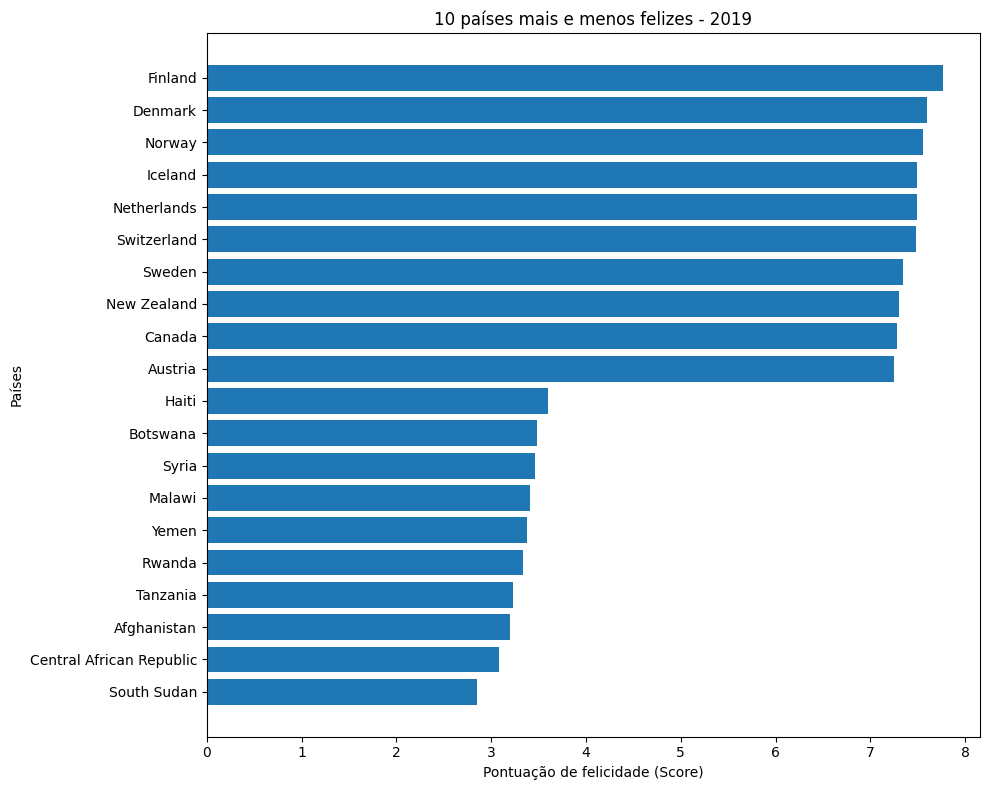

In [21]:
import matplotlib.pyplot as plt

# Juntando os dois grupos
comparacao = pd.concat([top_10, bottom_10])

# Ordenando pela pontuação
comparacao = comparacao.sort_values("Score")

# Criando o gráfico
plt.figure(figsize=(10, 8))

plt.barh(
    comparacao["Country or region"],
    comparacao["Score"]
)

plt.title("10 países mais e menos felizes - 2019")
plt.xlabel("Pontuação de felicidade (Score)")
plt.ylabel("Países")

plt.tight_layout()
plt.show()

### Comparação entre os países mais e menos felizes

Ao observar o ranking de felicidade de 2019, percebemos que a Finlândia ficou em primeiro lugar, com 7,769 pontos. Já o Sudão do Sul ficou na última posição, com apenas 2,853 pontos.

Entre os dez países mais bem colocados, a maioria é europeia, principalmente da região nórdica. Por outro lado, entre os dez últimos colocados, aparecem principalmente países da África e da Ásia.

A diferença entre o país com maior e menor pontuação foi de 4,916 pontos, mostrando que existem grandes diferenças nos níveis de felicidade entre os países analisados.

Esses dados mostram que os países apresentam realidades bastante diferentes, mas ainda não explicam o motivo dessas diferenças. Para entender melhor essa questão, será necessário observar outros fatores, como a economia e as condições de vida da população.

Quais indicadores apresentam maior associação com a pontuação de felicidade dos países?

In [22]:
# Calculando a correlação entre os indicadores
correlacoes = df[indicadores].corr(method="pearson")

# Exibindo a correlação de cada indicador com o Score
correlacao_score = correlacoes["Score"].sort_values(
    ascending=False
)

display(correlacao_score)

,Score
Score,1.000000
GDP per capita,0.793883
Healthy life expectancy,0.779883
Social support,0.777058
Freedom to make life choices,0.566742
Perceptions of corruption,0.385613
Generosity,0.075824


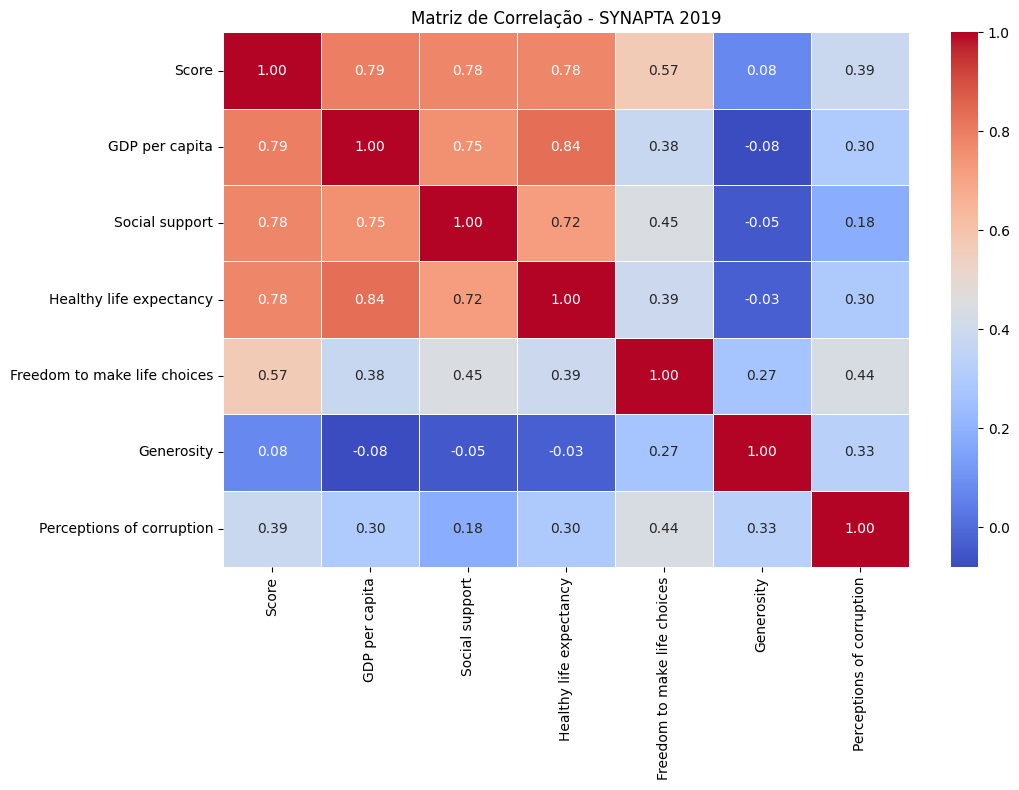

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculando a matriz de correlação
matriz_corr = df[indicadores].corr()

# Criando o tamanho da figura
plt.figure(figsize=(11, 8))

# Construindo o mapa de calor
sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de Correlação - SYNAPTA 2019")
plt.tight_layout()
plt.show()

### Relação entre os indicadores e a felicidade

Ao observar os dados de 2019, podemos perceber que alguns fatores têm uma relação maior com a felicidade das pessoas do que outros.

O dinheiro foi o fator que mais se destacou, com uma pontuação de 0,794. Em seguida, aparecem a expectativa de viver com saúde, com 0,780, e o apoio recebido de outras pessoas, com 0,777.

A liberdade para fazer escolhas também teve uma relação considerável com a felicidade, alcançando 0,567. Já a percepção de corrupção apresentou um resultado menor, de 0,386.

Por outro lado, a generosidade foi o fator que menos se relacionou com a felicidade, apresentando apenas 0,076.

No geral, os resultados mostram que ter boas condições financeiras, viver com saúde e contar com o apoio de outras pessoas são fatores que aparecem mais ligados à felicidade dos países. Porém, isso não significa que esses fatores sejam os responsáveis diretos pela felicidade, mas apenas que existe uma relação entre eles nos dados analisados.